In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json
import plotly.express as px
import plotly.graph_objects as go


pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

In [2]:
NOTEBOOKS_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOKS_DIR.parent
DATA_PROCESSED_DIR = PROJECT_ROOT / "DATA" / "PROCESSED"

print("Project root:", PROJECT_ROOT)
print("Processed data directory:", DATA_PROCESSED_DIR)

Project root: C:\Users\sitar\Downloads\ASSIGNMENT_CODE\INDIAN PREMIER LEAGUE
Processed data directory: C:\Users\sitar\Downloads\ASSIGNMENT_CODE\INDIAN PREMIER LEAGUE\DATA\PROCESSED


In [3]:
deliveries_path = DATA_PROCESSED_DIR / "deliveries.csv"
matches_path = DATA_PROCESSED_DIR / "matches.csv"

if not deliveries_path.exists():
    raise FileNotFoundError(
        "deliveries.csv not found. Run Notebook 02 first."
    )

if not matches_path.exists():
    raise FileNotFoundError(
        "matches.csv not found. Run Notebook 02 first."
    )

deliveries_df = pd.read_csv(
    deliveries_path,
    low_memory=False
)
matches_df = pd.read_csv(matches_path)

print("Deliveries shape:", deliveries_df.shape)
print("Matches shape:", matches_df.shape)

display(deliveries_df.head())
display(matches_df.head())


Deliveries shape: (295732, 27)
Matches shape: (1243, 26)


,match_id,season,start_date,venue,innings,ball,actual_delivery,batting_team,bowling_team,striker,non_striker,bowler,runs_off_bat,extras,wides,noballs,byes,legbyes,penalty,non_boundary,wicket_type,player_dismissed,other_wicket_type,other_player_dismissed,fielder_1,fielder_2,fielder_3
0,1082591,2017.0,2017-04-05,"Rajiv Gandhi International Stadium, Uppal",1,0.1,0.1,Sunrisers Hyderabad,Royal Challengers Bangalore,DA Warner,S Dhawan,TS Mills,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1082591,2017.0,2017-04-05,"Rajiv Gandhi International Stadium, Uppal",1,0.2,0.2,Sunrisers Hyderabad,Royal Challengers Bangalore,DA Warner,S Dhawan,TS Mills,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1082591,2017.0,2017-04-05,"Rajiv Gandhi International Stadium, Uppal",1,0.3,0.3,Sunrisers Hyderabad,Royal Challengers Bangalore,DA Warner,S Dhawan,TS Mills,4,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1082591,2017.0,2017-04-05,"Rajiv Gandhi International Stadium, Uppal",1,0.4,0.4,Sunrisers Hyderabad,Royal Challengers Bangalore,DA Warner,S Dhawan,TS Mills,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1082591,2017.0,2017-04-05,"Rajiv Gandhi International Stadium, Uppal",1,0.5,0.5,Sunrisers Hyderabad,Royal Challengers Bangalore,DA Warner,S Dhawan,TS Mills,0,2,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,match_id,season,date,event,match_type,match_number,gender,team_1,team_2,venue,city,toss_winner,toss_decision,player_of_match,winner,winner_runs,winner_wickets,overs,balls_per_over,target_runs,target_overs,team_1_players,team_2_players,umpires,match_referee,info_version
0,1082591,2017.0,2017-04-05,Indian Premier League,T20,1.0,male,Sunrisers Hyderabad,Royal Challengers Bangalore,"Rajiv Gandhi International Stadium, Uppal",Hyderabad,Royal Challengers Bangalore,field,Yuvraj Singh,Sunrisers Hyderabad,35.0,NaN,20,6,208.0,20.0,DA Warner | S Dhawan | MC Henriques | Yuvraj S...,CH Gayle | Mandeep Singh | TM Head | KM Jadhav...,AY Dandekar | NJ Llong,J Srinath,2.3.0
1,1082592,2017.0,2017-04-06,Indian Premier League,T20,2.0,male,Rising Pune Supergiant,Mumbai Indians,Maharashtra Cricket Association Stadium,Pune,Rising Pune Supergiant,field,SPD Smith,Rising Pune Supergiant,NaN,7.0,20,6,185.0,20.0,AM Rahane | MA Agarwal | SPD Smith | BA Stokes...,PA Patel | JC Buttler | RG Sharma | N Rana | A...,A Nand Kishore | S Ravi,M Nayyar,2.3.0
2,1082593,2017.0,2017-04-07,Indian Premier League,T20,3.0,male,Gujarat Lions,Kolkata Knight Riders,Saurashtra Cricket Association Stadium,Rajkot,Kolkata Knight Riders,field,CA Lynn,Kolkata Knight Riders,NaN,10.0,20,6,184.0,20.0,JJ Roy | BB McCullum | SK Raina | AJ Finch | K...,G Gambhir | CA Lynn | RV Uthappa | MK Pandey |...,Nitin Menon | CK Nandan,V Narayan Kutty,2.3.0
3,1082594,2017.0,2017-04-08,Indian Premier League,T20,4.0,male,Kings XI Punjab,Rising Pune Supergiant,Holkar Cricket Stadium,Indore,Kings XI Punjab,field,GJ Maxwell,Kings XI Punjab,NaN,6.0,20,6,164.0,20.0,HM Amla | M Vohra | WP Saha | AR Patel | GJ Ma...,AM Rahane | MA Agarwal | SPD Smith | BA Stokes...,AK Chaudhary | C Shamshuddin,Chinmay Sharma,2.3.0
4,1082595,2017.0,2017-04-08,Indian Premier League,T20,5.0,male,Royal Challengers Bangalore,Delhi Daredevils,M.Chinnaswamy Stadium,Bengaluru,Royal Challengers Bangalore,bat,KM Jadhav,Royal Challengers Bangalore,15.0,NaN,20,6,158.0,20.0,CH Gayle | SR Watson | Mandeep Singh | KM Jadh...,AP Tare | SW Billings | KK Nair | SV Samson | ...,S Ravi | VK Sharma,J Srinath,2.3.0


In [4]:
if "start_date" in deliveries_df.columns:
    deliveries_df["start_date"] = pd.to_datetime(
        deliveries_df["start_date"], errors="coerce"
    )

if "date" in matches_df.columns:
    matches_df["date"] = pd.to_datetime(
        matches_df["date"], errors="coerce"
    )

for df in [deliveries_df, matches_df]:
    if "season" in df.columns:
        df["season"] = df["season"].astype("string")

print("Delivery data types:")
display(deliveries_df.dtypes.to_frame("dtype"))

print("Match data types:")
display(matches_df.dtypes.to_frame("dtype"))


Delivery data types:


,dtype
match_id,int64
season,string[python]
start_date,datetime64[ns]
venue,object
innings,int64
ball,float64
actual_delivery,float64
batting_team,object
bowling_team,object
striker,object


Match data types:


,dtype
match_id,int64
season,string[python]
date,datetime64[ns]
event,object
match_type,object
match_number,float64
gender,object
team_1,object
team_2,object
venue,object


In [5]:
print("IPL DATASET OVERVIEW")
print("=" * 50)

print("Total delivery records:", len(deliveries_df))
print("Unique matches in deliveries:", deliveries_df["match_id"].nunique())
print("Match metadata records:", len(matches_df))

if "season" in matches_df.columns:
    print("Unique seasons:", matches_df["season"].nunique())

if "team_1" in matches_df.columns and "team_2" in matches_df.columns:
    all_teams = pd.concat(
        [matches_df["team_1"], matches_df["team_2"]],
        ignore_index=True
    ).dropna()

    print("Unique team names:", all_teams.nunique())

print("\nDelivery columns:")
print(deliveries_df.columns.tolist())


IPL DATASET OVERVIEW
Total delivery records: 295732
Unique matches in deliveries: 1243
Match metadata records: 1243
Unique seasons: 16
Unique team names: 19

Delivery columns:
['match_id', 'season', 'start_date', 'venue', 'innings', 'ball', 'actual_delivery', 'batting_team', 'bowling_team', 'striker', 'non_striker', 'bowler', 'runs_off_bat', 'extras', 'wides', 'noballs', 'byes', 'legbyes', 'penalty', 'non_boundary', 'wicket_type', 'player_dismissed', 'other_wicket_type', 'other_player_dismissed', 'fielder_1', 'fielder_2', 'fielder_3']


,season,matches
0,2009.0,57
1,2011.0,73
2,2012.0,74
3,2013.0,76
4,2014.0,60
5,2015.0,59
6,2016.0,60
7,2017.0,59
8,2018.0,60
9,2019.0,60


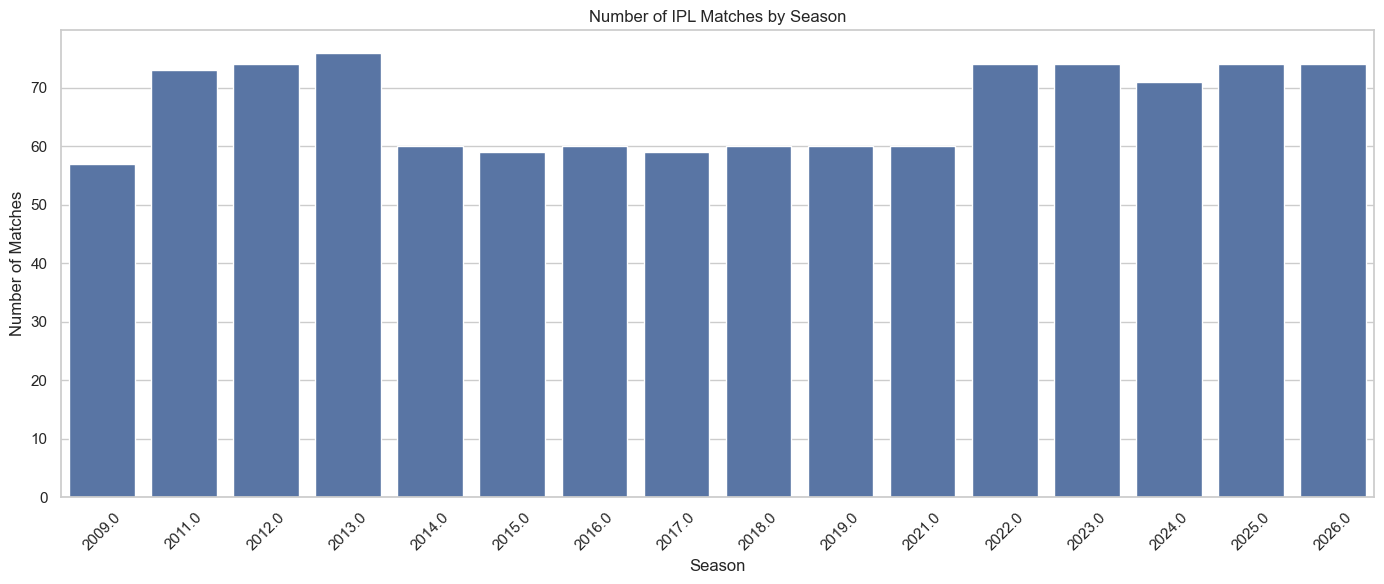

In [6]:
if "season" in matches_df.columns:
    matches_by_season = (
        matches_df.groupby("season")
        .size()
        .reset_index(name="matches")
        .sort_values("season")
    )

    display(matches_by_season)

    plt.figure(figsize=(14, 6))
    sns.barplot(
        data=matches_by_season,
        x="season",
        y="matches"
    )
    plt.title("Number of IPL Matches by Season")
    plt.xlabel("Season")
    plt.ylabel("Number of Matches")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()


,season,total_runs
0,2009.0,16353
1,2011.0,21154
2,2012.0,22453
3,2013.0,22602
4,2014.0,18931
5,2015.0,18353
6,2016.0,18862
7,2017.0,18786
8,2018.0,19901
9,2019.0,19434


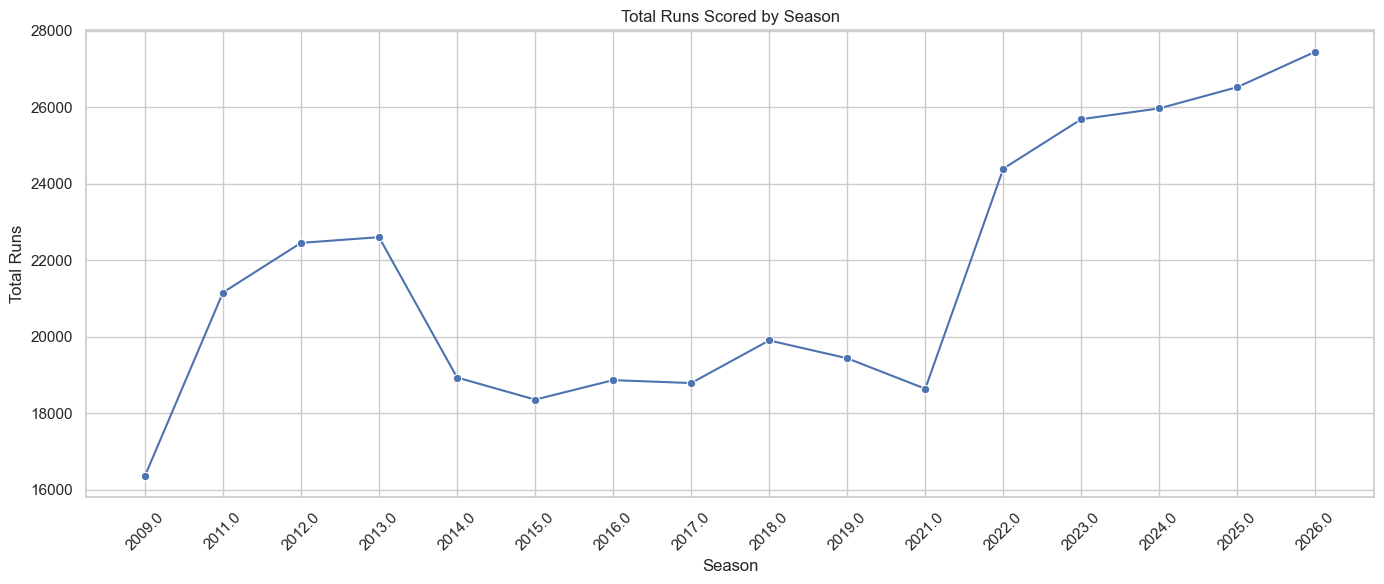

In [7]:
required_run_columns = ["runs_off_bat", "extras"]

for column in required_run_columns:
    if column not in deliveries_df.columns:
        raise ValueError(f"Required column missing: {column}")

deliveries_df["runs_off_bat"] = pd.to_numeric(
    deliveries_df["runs_off_bat"], errors="coerce"
).fillna(0)

deliveries_df["extras"] = pd.to_numeric(
    deliveries_df["extras"], errors="coerce"
).fillna(0)

deliveries_df["total_runs"] = (
    deliveries_df["runs_off_bat"] + deliveries_df["extras"]
)

if "season" in deliveries_df.columns:
    runs_by_season = (
        deliveries_df.groupby("season")["total_runs"]
        .sum()
        .reset_index(name="total_runs")
        .sort_values("season")
    )

    display(runs_by_season)

    plt.figure(figsize=(14, 6))
    sns.lineplot(
        data=runs_by_season,
        x="season",
        y="total_runs",
        marker="o"
    )
    plt.title("Total Runs Scored by Season")
    plt.xlabel("Season")
    plt.ylabel("Total Runs")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()


,batting_team,total_runs
0,Mumbai Indians,47641
1,Kolkata Knight Riders,43646
2,Chennai Super Kings,43600
3,Rajasthan Royals,40437
4,Royal Challengers Bangalore,37692
5,Sunrisers Hyderabad,34640
6,Kings XI Punjab,30064
7,Delhi Daredevils,24296
8,Delhi Capitals,19959
9,Punjab Kings,15509


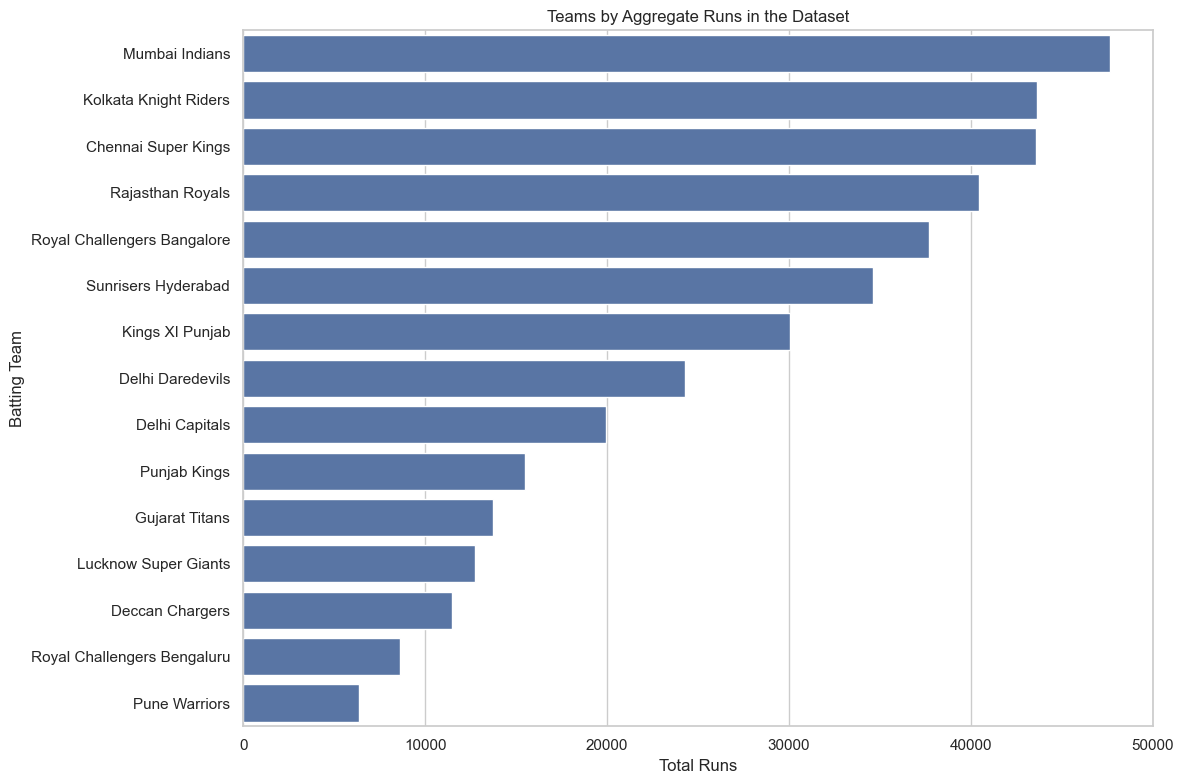

In [8]:
if "batting_team" in deliveries_df.columns:
    team_runs = (
        deliveries_df.groupby("batting_team")["total_runs"]
        .sum()
        .sort_values(ascending=False)
        .reset_index(name="total_runs")
    )

    display(team_runs)

    plt.figure(figsize=(12, 8))
    sns.barplot(
        data=team_runs.head(15),
        y="batting_team",
        x="total_runs"
    )
    plt.title("Teams by Aggregate Runs in the Dataset")
    plt.xlabel("Total Runs")
    plt.ylabel("Batting Team")
    plt.tight_layout()
    plt.show()


Top 20 run scorers in the dataset:


,striker,runs
0,V Kohli,9346
1,RG Sharma,7331
2,S Dhawan,6769
3,DA Warner,6567
4,KL Rahul,5828
5,SK Raina,5536
6,MS Dhoni,5439
7,AM Rahane,5367
8,SV Samson,5181
9,AB de Villiers,5181


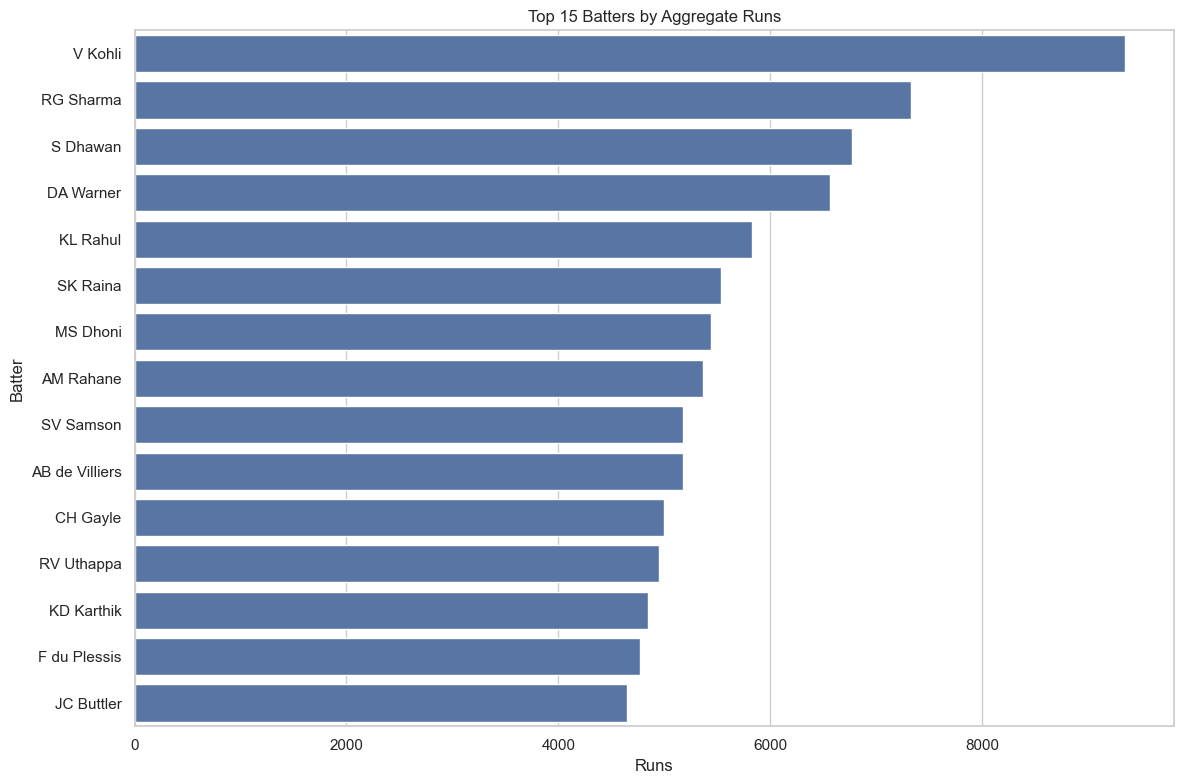

In [9]:
if {"striker", "runs_off_bat"}.issubset(deliveries_df.columns):
    batter_runs = (
        deliveries_df.groupby("striker")["runs_off_bat"]
        .sum()
        .sort_values(ascending=False)
        .reset_index(name="runs")
    )

    print("Top 20 run scorers in the dataset:")
    display(batter_runs.head(20))

    plt.figure(figsize=(12, 8))
    sns.barplot(
        data=batter_runs.head(15),
        y="striker",
        x="runs"
    )
    plt.title("Top 15 Batters by Aggregate Runs")
    plt.xlabel("Runs")
    plt.ylabel("Batter")
    plt.tight_layout()
    plt.show()


Venues with the most recorded matches:


,venue,matches
14,Eden Gardens,77
57,Wankhede Stadium,73
23,M Chinnaswamy Stadium,65
16,Feroz Shah Kotla,60
58,"Wankhede Stadium, Mumbai",59
43,"Rajiv Gandhi International Stadium, Uppal",49
27,"MA Chidambaram Stadium, Chepauk",48
47,Sawai Mansingh Stadium,47
13,Dubai International Cricket Stadium,46
33,"Narendra Modi Stadium, Ahmedabad",41


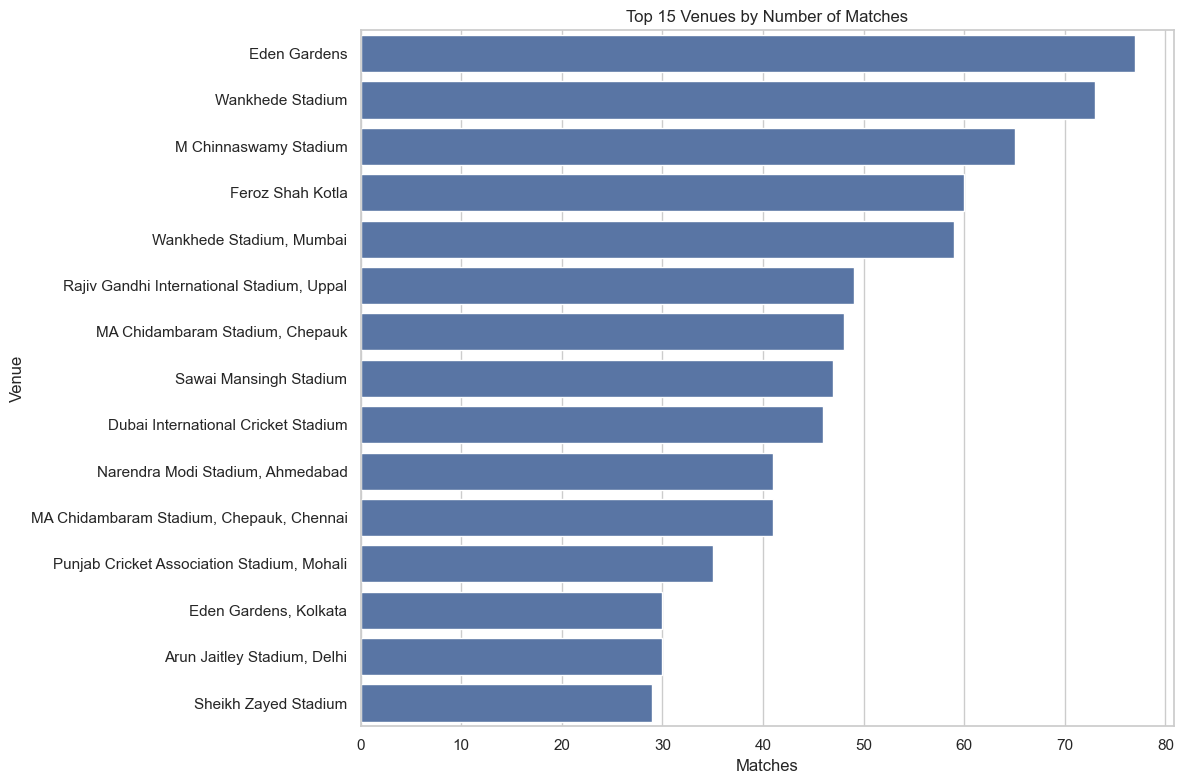

In [10]:
if "venue" in matches_df.columns:
    venue_matches = (
        matches_df.groupby("venue")
        .size()
        .reset_index(name="matches")
        .sort_values("matches", ascending=False)
    )

    print("Venues with the most recorded matches:")
    display(venue_matches.head(15))

    plt.figure(figsize=(12, 8))
    sns.barplot(
        data=venue_matches.head(15),
        y="venue",
        x="matches"
    )
    plt.title("Top 15 Venues by Number of Matches")
    plt.xlabel("Matches")
    plt.ylabel("Venue")
    plt.tight_layout()
    plt.show()


,toss_decision,matches
0,field,825
1,bat,418


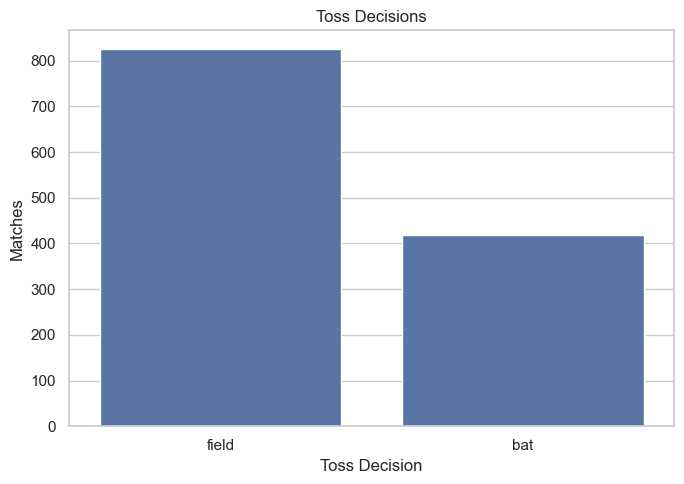

,toss_winner_won_match,matches
0,True,628
1,False,590


In [11]:
if "toss_decision" in matches_df.columns:
    toss_summary = (
        matches_df["toss_decision"]
        .fillna("Unknown")
        .value_counts()
        .rename_axis("toss_decision")
        .reset_index(name="matches")
    )

    display(toss_summary)

    plt.figure(figsize=(7, 5))
    sns.barplot(
        data=toss_summary,
        x="toss_decision",
        y="matches"
    )
    plt.title("Toss Decisions")
    plt.xlabel("Toss Decision")
    plt.ylabel("Matches")
    plt.tight_layout()
    plt.show()

if {"toss_winner", "winner"}.issubset(matches_df.columns):
    toss_result_df = matches_df.dropna(
        subset=["toss_winner", "winner"]
    ).copy()

    toss_result_df["toss_winner_won_match"] = (
        toss_result_df["toss_winner"] == toss_result_df["winner"]
    )

    toss_result_summary = (
        toss_result_df["toss_winner_won_match"]
        .value_counts()
        .rename_axis("toss_winner_won_match")
        .reset_index(name="matches")
    )

    display(toss_result_summary)


Sample innings totals:


,match_id,innings,batting_team,total_runs,delivery_records
0,335982,1,Kolkata Knight Riders,222,124
1,335982,2,Royal Challengers Bangalore,82,101
2,335983,1,Chennai Super Kings,240,124
3,335983,2,Kings XI Punjab,207,124
4,335984,1,Rajasthan Royals,129,122
5,335984,2,Delhi Daredevils,132,97
6,335985,1,Mumbai Indians,165,123
7,335985,2,Royal Challengers Bangalore,166,123
8,335986,1,Deccan Chargers,110,118
9,335986,2,Kolkata Knight Riders,112,122


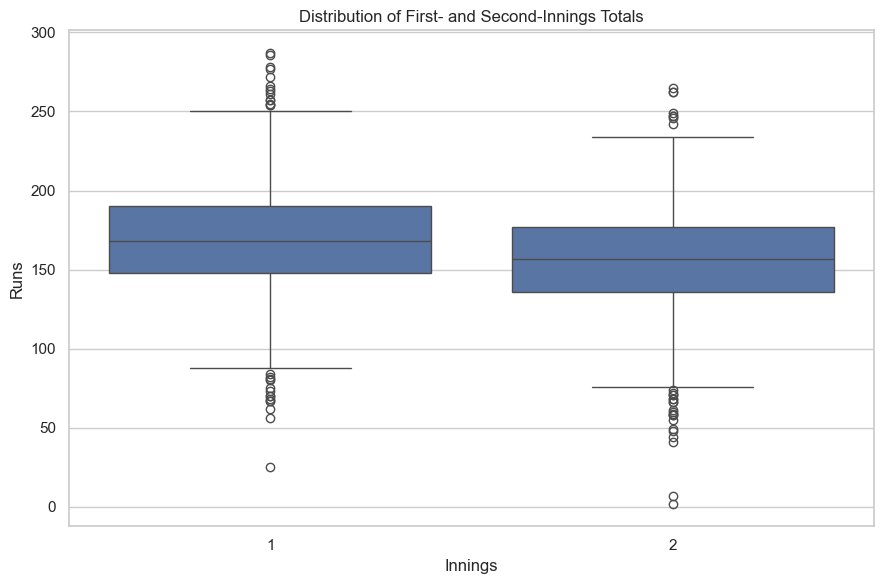

In [12]:
if "innings" in deliveries_df.columns:
    innings_summary = (
        deliveries_df.groupby(["match_id", "innings"])
        .agg(
            batting_team=("batting_team", "first"),
            total_runs=("total_runs", "sum"),
            delivery_records=("match_id", "size")
        )
        .reset_index()
    )

    print("Sample innings totals:")
    display(innings_summary.head(20))

    plt.figure(figsize=(9, 6))
    sns.boxplot(
        data=innings_summary[innings_summary["innings"].isin([1, 2])],
        x="innings",
        y="total_runs"
    )
    plt.title("Distribution of First- and Second-Innings Totals")
    plt.xlabel("Innings")
    plt.ylabel("Runs")
    plt.tight_layout()
    plt.show()


In [13]:
def missing_summary(df):
    result = pd.DataFrame({
        "missing_count": df.isna().sum(),
        "missing_percentage": (
            df.isna().mean() * 100
        ).round(2)
    })

    return result.sort_values(
        "missing_percentage", ascending=False
    )

print("Delivery dataset:")
display(missing_summary(deliveries_df))

print("Match dataset:")
display(missing_summary(matches_df))


Delivery dataset:


,missing_count,missing_percentage
other_player_dismissed,295732,100.00
other_wicket_type,295732,100.00
fielder_3,295719,100.00
penalty,295730,100.00
non_boundary,295703,99.99
fielder_2,295200,99.82
byes,294987,99.75
noballs,294506,99.59
legbyes,291326,98.51
wides,285856,96.66


Match dataset:


,missing_count,missing_percentage
winner_runs,685,55.11
winner_wickets,583,46.90
season,178,14.32
match_number,74,5.95
city,51,4.10
winner,25,2.01
player_of_match,9,0.72
target_overs,7,0.56
target_runs,6,0.48
match_id,0,0.00


In [14]:
# Save selected summary tables for reuse in the dashboard.

eda_output_dir = DATA_PROCESSED_DIR / "EDA"
eda_output_dir.mkdir(parents=True, exist_ok=True)

summary_tables = {}

if "season" in matches_df.columns:
    summary_tables["matches_by_season"] = (
        matches_df.groupby("season")
        .size()
        .reset_index(name="matches")
    )

summary_tables["team_runs"] = (
    deliveries_df.groupby("batting_team")["total_runs"]
    .sum()
    .sort_values(ascending=False)
    .reset_index(name="total_runs")
)

summary_tables["batter_runs"] = (
    deliveries_df.groupby("striker")["runs_off_bat"]
    .sum()
    .sort_values(ascending=False)
    .reset_index(name="runs")
)

for name, table in summary_tables.items():
    output_path = eda_output_dir / f"{name}.csv"
    table.to_csv(output_path, index=False)
    print("Saved:", output_path)

print("\nEDA summary tables saved successfully.")


Saved: C:\Users\sitar\Downloads\ASSIGNMENT_CODE\INDIAN PREMIER LEAGUE\DATA\PROCESSED\EDA\matches_by_season.csv
Saved: C:\Users\sitar\Downloads\ASSIGNMENT_CODE\INDIAN PREMIER LEAGUE\DATA\PROCESSED\EDA\team_runs.csv
Saved: C:\Users\sitar\Downloads\ASSIGNMENT_CODE\INDIAN PREMIER LEAGUE\DATA\PROCESSED\EDA\batter_runs.csv

EDA summary tables saved successfully.


In [15]:
GEO_OUTPUT_DIR = DATA_PROCESSED_DIR / "GEOGRAPHIC"
GEO_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Put an India states GeoJSON boundary file at either of these locations.
GEOJSON_CANDIDATES = [
    DATA_PROCESSED_DIR / "india_states.geojson",
    PROJECT_ROOT / "DATA" / "RAW" / "india_states.geojson",
    PROJECT_ROOT / "DATA" / "GEOJSON" / "india_states.geojson",
]
INDIA_STATES_GEOJSON = next(
    (path for path in GEOJSON_CANDIDATES if path.exists()),
    None
)

print("Geographic outputs:", GEO_OUTPUT_DIR)
print("State GeoJSON:", INDIA_STATES_GEOJSON or "Not found yet")


Geographic outputs: C:\Users\sitar\Downloads\ASSIGNMENT_CODE\INDIAN PREMIER LEAGUE\DATA\PROCESSED\GEOGRAPHIC
State GeoJSON: Not found yet


In [16]:
# Common IPL venue aliases mapped to city, state, latitude, and longitude.
# Treat this as a starting lookup and verify against the actual venue names in your dataset.
# Add or correct rows if your dataset contains additional or differently named venues.
venue_location_records = [
    {"venue_key": "M Chinnaswamy Stadium", "city": "Bengaluru", "state": "Karnataka", "latitude": 12.9788, "longitude": 77.5996},
    {"venue_key": "M. Chinnaswamy Stadium", "city": "Bengaluru", "state": "Karnataka", "latitude": 12.9788, "longitude": 77.5996},
    {"venue_key": "Wankhede Stadium", "city": "Mumbai", "state": "Maharashtra", "latitude": 18.9389, "longitude": 72.8258},
    {"venue_key": "Brabourne Stadium", "city": "Mumbai", "state": "Maharashtra", "latitude": 18.9322, "longitude": 72.8258},
    {"venue_key": "Eden Gardens", "city": "Kolkata", "state": "West Bengal", "latitude": 22.5646, "longitude": 88.3433},
    {"venue_key": "Arun Jaitley Stadium", "city": "Delhi", "state": "Delhi", "latitude": 28.6377, "longitude": 77.2432},
    {"venue_key": "Feroz Shah Kotla", "city": "Delhi", "state": "Delhi", "latitude": 28.6377, "longitude": 77.2432},
    {"venue_key": "Rajiv Gandhi International Stadium", "city": "Hyderabad", "state": "Telangana", "latitude": 17.4065, "longitude": 78.5505},
    {"venue_key": "Rajiv Gandhi Intl. Cricket Stadium", "city": "Hyderabad", "state": "Telangana", "latitude": 17.4065, "longitude": 78.5505},
    {"venue_key": "MA Chidambaram Stadium", "city": "Chennai", "state": "Tamil Nadu", "latitude": 13.0627, "longitude": 80.2792},
    {"venue_key": "M.A. Chidambaram Stadium", "city": "Chennai", "state": "Tamil Nadu", "latitude": 13.0627, "longitude": 80.2792},
    {"venue_key": "Sawai Mansingh Stadium", "city": "Jaipur", "state": "Rajasthan", "latitude": 26.8940, "longitude": 75.8030},
    {"venue_key": "Punjab Cricket Association IS Bindra Stadium", "city": "Mohali", "state": "Punjab", "latitude": 30.6900, "longitude": 76.7370},
    {"venue_key": "Punjab Cricket Association Stadium", "city": "Mohali", "state": "Punjab", "latitude": 30.6900, "longitude": 76.7370},
    {"venue_key": "Himachal Pradesh Cricket Association Stadium", "city": "Dharamshala", "state": "Himachal Pradesh", "latitude": 32.1970, "longitude": 76.3250},
    {"venue_key": "Narendra Modi Stadium", "city": "Ahmedabad", "state": "Gujarat", "latitude": 23.0918, "longitude": 72.5970},
    {"venue_key": "Sardar Patel Stadium", "city": "Ahmedabad", "state": "Gujarat", "latitude": 23.0918, "longitude": 72.5970},
    {"venue_key": "Dr DY Patil Sports Academy", "city": "Navi Mumbai", "state": "Maharashtra", "latitude": 19.0437, "longitude": 73.0260},
    {"venue_key": "Dr. Y.S. Rajasekhara Reddy ACA-VDCA Cricket Stadium", "city": "Visakhapatnam", "state": "Andhra Pradesh", "latitude": 17.7970, "longitude": 83.3520},
    {"venue_key": "ACA-VDCA Cricket Stadium", "city": "Visakhapatnam", "state": "Andhra Pradesh", "latitude": 17.7970, "longitude": 83.3520},
    {"venue_key": "Barsapara Cricket Stadium", "city": "Guwahati", "state": "Assam", "latitude": 26.1445, "longitude": 91.7362},
    {"venue_key": "Bharat Ratna Shri Atal Bihari Vajpayee Ekana Cricket Stadium", "city": "Lucknow", "state": "Uttar Pradesh", "latitude": 26.8120, "longitude": 80.9900},
    {"venue_key": "Ekana Cricket Stadium", "city": "Lucknow", "state": "Uttar Pradesh", "latitude": 26.8120, "longitude": 80.9900},
    {"venue_key": "JSCA International Stadium Complex", "city": "Ranchi", "state": "Jharkhand", "latitude": 23.3070, "longitude": 85.2790},
    {"venue_key": "Shaheed Veer Narayan Singh International Stadium", "city": "Raipur", "state": "Chhattisgarh", "latitude": 21.2120, "longitude": 81.8000},
    {"venue_key": "Maharashtra Cricket Association Stadium", "city": "Pune", "state": "Maharashtra", "latitude": 18.6720, "longitude": 73.7060},
    {"venue_key": "Holkar Cricket Stadium", "city": "Indore", "state": "Madhya Pradesh", "latitude": 22.7240, "longitude": 75.8790},
    {"venue_key": "Green Park", "city": "Kanpur", "state": "Uttar Pradesh", "latitude": 26.4820, "longitude": 80.3550},
    {"venue_key": "ACA Stadium", "city": "Guwahati", "state": "Assam", "latitude": 26.1445, "longitude": 91.7362},
]

venue_locations_df = pd.DataFrame(venue_location_records).drop_duplicates(
    subset=["venue_key"], keep="first"
)

if "venue" not in matches_df.columns:
    raise KeyError("The matches table needs a 'venue' column for geographic analysis.")

venue_statistics = (
    matches_df.dropna(subset=["venue"])
    .groupby("venue", dropna=False)
    .agg(matches=("venue", "size"))
    .reset_index()
    .sort_values("matches", ascending=False)
)

# Match venue names using case-insensitive substring checks; unmatched venues remain visible.
def match_venue_location(venue_name):
    venue_text = str(venue_name).strip().casefold()
    for record in venue_location_records:
        key = record["venue_key"].casefold()
        if key in venue_text or venue_text in key:
            return record
    return None

location_rows = []
for venue_name in venue_statistics["venue"]:
    matched = match_venue_location(venue_name)
    if matched:
        location_rows.append({"venue": venue_name, **{k: v for k, v in matched.items() if k != "venue_key"}})
    else:
        location_rows.append({
            "venue": venue_name, "city": None, "state": None,
            "latitude": np.nan, "longitude": np.nan
        })

venue_locations_df = pd.DataFrame(location_rows)
venue_statistics_df = venue_statistics.merge(
    venue_locations_df, on="venue", how="left"
)

# Where total_runs exists in the delivery table, calculate match totals and average scores.
if {"match_id", "total_runs"}.issubset(deliveries_df.columns):
    match_scores = (
        deliveries_df.groupby("match_id")["total_runs"]
        .sum()
        .rename("match_total_runs")
        .reset_index()
    )
    match_venue = matches_df[["match_id", "venue"]].drop_duplicates("match_id")
    venue_scores = match_venue.merge(match_scores, on="match_id", how="left")
    venue_scores = (
        venue_scores.groupby("venue")["match_total_runs"]
        .agg(average_match_total="mean", highest_match_total="max")
        .reset_index()
    )
    venue_statistics_df = venue_statistics_df.merge(
        venue_scores, on="venue", how="left"
    )

venue_locations_df.to_csv(GEO_OUTPUT_DIR / "venue_locations.csv", index=False)
venue_statistics_df.to_csv(GEO_OUTPUT_DIR / "venue_statistics.csv", index=False)

print("Venue rows:", len(venue_statistics_df))
print("Venues with coordinates:", int(venue_statistics_df["latitude"].notna().sum()))
print("Venues needing a coordinate lookup:", int(venue_statistics_df["latitude"].isna().sum()))
display(venue_statistics_df.head(20))


Venue rows: 60
Venues with coordinates: 40
Venues needing a coordinate lookup: 20


,venue,matches,city,state,latitude,longitude,average_match_total,highest_match_total
0,Eden Gardens,77,Kolkata,West Bengal,22.5646,88.3433,307.246753,430
1,Wankhede Stadium,73,Mumbai,Maharashtra,18.9389,72.8258,320.643836,453
2,M Chinnaswamy Stadium,65,Bengaluru,Karnataka,12.9788,77.5996,311.738462,409
3,Feroz Shah Kotla,60,Delhi,Delhi,28.6377,77.2432,307.016667,433
4,"Wankhede Stadium, Mumbai",59,Mumbai,Maharashtra,18.9389,72.8258,353.440678,492
5,"Rajiv Gandhi International Stadium, Uppal",49,Hyderabad,Telangana,17.4065,78.5505,303.836735,431
6,"MA Chidambaram Stadium, Chepauk",48,Chennai,Tamil Nadu,13.0627,80.2792,318.270833,469
7,Sawai Mansingh Stadium,47,Jaipur,Rajasthan,26.8940,75.8030,303.489362,393
8,Dubai International Cricket Stadium,46,None,None,NaN,NaN,314.130435,420
9,"Narendra Modi Stadium, Ahmedabad",41,Ahmedabad,Gujarat,23.0918,72.5970,351.902439,475


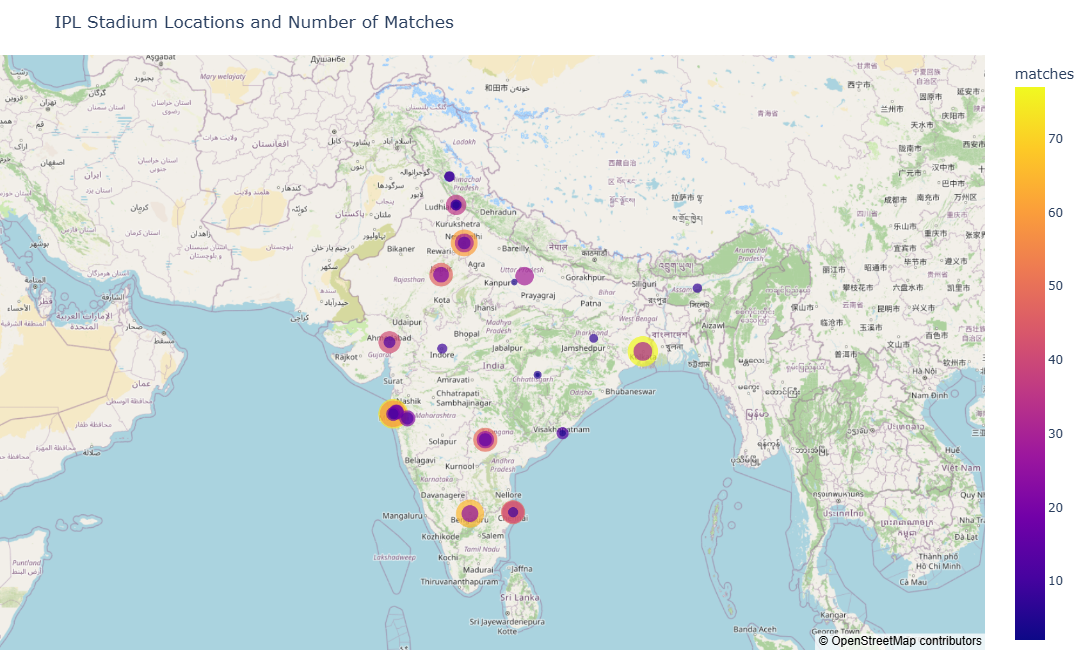

In [20]:
mapped_venues = venue_statistics_df.dropna(subset=["latitude", "longitude"]).copy()

if mapped_venues.empty:
    print(
        "No venue names matched the coordinate lookup yet. "
        "Review venue_statistics.csv and add aliases to venue_location_records."
    )
else:
    hover_columns = {
        "matches": True,
        "city": True,
        "state": True,
    }
    if "average_match_total" in mapped_venues.columns:
        hover_columns["average_match_total"] = ":.1f"
    if "highest_match_total" in mapped_venues.columns:
        hover_columns["highest_match_total"] = True

    fig = px.scatter_map(
        mapped_venues,
        lat="latitude",
        lon="longitude",
        size="matches",
        color="matches",
        hover_name="venue",
        hover_data=hover_columns,
        zoom=3.5,
        center={"lat": 22.5, "lon": 79.0},
        map_style="open-street-map",
        title="IPL Stadium Locations and Number of Matches",
        size_max=22,
    )
    fig.update_layout(height=650, margin={"r": 0, "t": 55, "l": 0, "b": 0})
    fig.show()


In [18]:
state_statistics_df = (
    venue_statistics_df.dropna(subset=["state"])
    .groupby("state")
    .agg(
        matches_hosted=("matches", "sum"),
        stadiums=("venue", "nunique"),
    )
    .reset_index()
    .sort_values("matches_hosted", ascending=False)
)

state_statistics_df.to_csv(GEO_OUTPUT_DIR / "state_statistics.csv", index=False)
display(state_statistics_df)

if INDIA_STATES_GEOJSON is None:
    print(
        "State choropleth not rendered because an India states GeoJSON file was not found. "
        "Place a GeoJSON file at DATA/PROCESSED/india_states.geojson "
        "(or one of the configured alternative paths), then rerun this cell."
    )
else:
    with open(INDIA_STATES_GEOJSON, "r", encoding="utf-8") as geo_file:
        india_states_geojson = json.load(geo_file)

    # Inspect GeoJSON property names if the state-name field differs from these common options.
    first_feature = india_states_geojson["features"][0]
    print("GeoJSON properties:", list(first_feature.get("properties", {}).keys()))

    possible_state_fields = [
        "ST_NM", "state", "State", "NAME_1", "name", "NAME"
    ]
    geo_state_field = next(
        (
            field for field in possible_state_fields
            if field in first_feature.get("properties", {})
        ),
        None
    )

    if geo_state_field is None:
        raise ValueError(
            "Could not identify the state-name property in the GeoJSON. "
            "Inspect the printed properties and set geo_state_field manually."
        )

    fig_state = px.choropleth(
        state_statistics_df,
        geojson=india_states_geojson,
        locations="state",
        featureidkey=f"properties.{geo_state_field}",
        color="matches_hosted",
        hover_name="state",
        hover_data={"matches_hosted": True, "stadiums": True},
        title="IPL Matches Hosted by State",
        color_continuous_scale="YlOrRd",
    )
    fig_state.update_geos(fitbounds="locations", visible=False)
    fig_state.update_layout(height=650, margin={"r": 0, "t": 55, "l": 0, "b": 0})
    fig_state.show()


,state,matches_hosted,stadiums
9,Maharashtra,231,8
15,West Bengal,107,2
3,Delhi,104,3
12,Tamil Nadu,98,3
13,Telangana,90,3
7,Karnataka,89,2
11,Rajasthan,68,2
10,Punjab,61,4
4,Gujarat,53,2
14,Uttar Pradesh,33,2


State choropleth not rendered because an India states GeoJSON file was not found. Place a GeoJSON file at DATA/PROCESSED/india_states.geojson (or one of the configured alternative paths), then rerun this cell.


In [19]:
print("Geographic analytics outputs:")
for output_file in sorted(GEO_OUTPUT_DIR.glob("*.csv")):
    print("-", output_file.name)


Geographic analytics outputs:
- state_statistics.csv
- venue_locations.csv
- venue_statistics.csv
